# Module 3: Semantic Caching with Embeddings
---

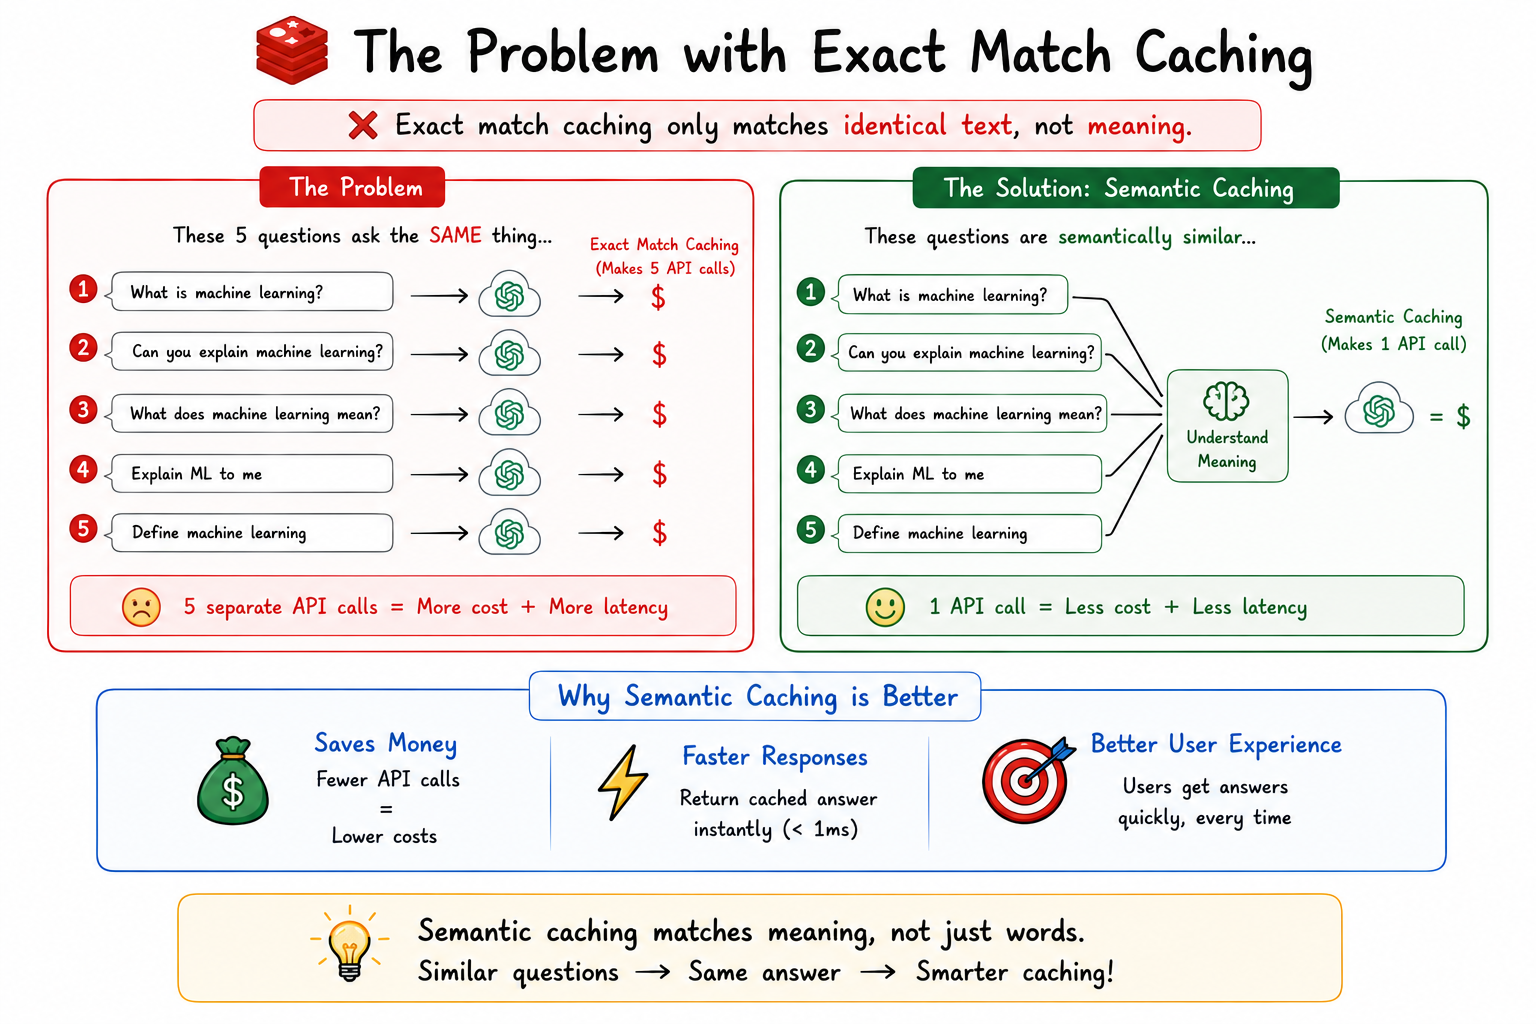

## 1. What are Embeddings?

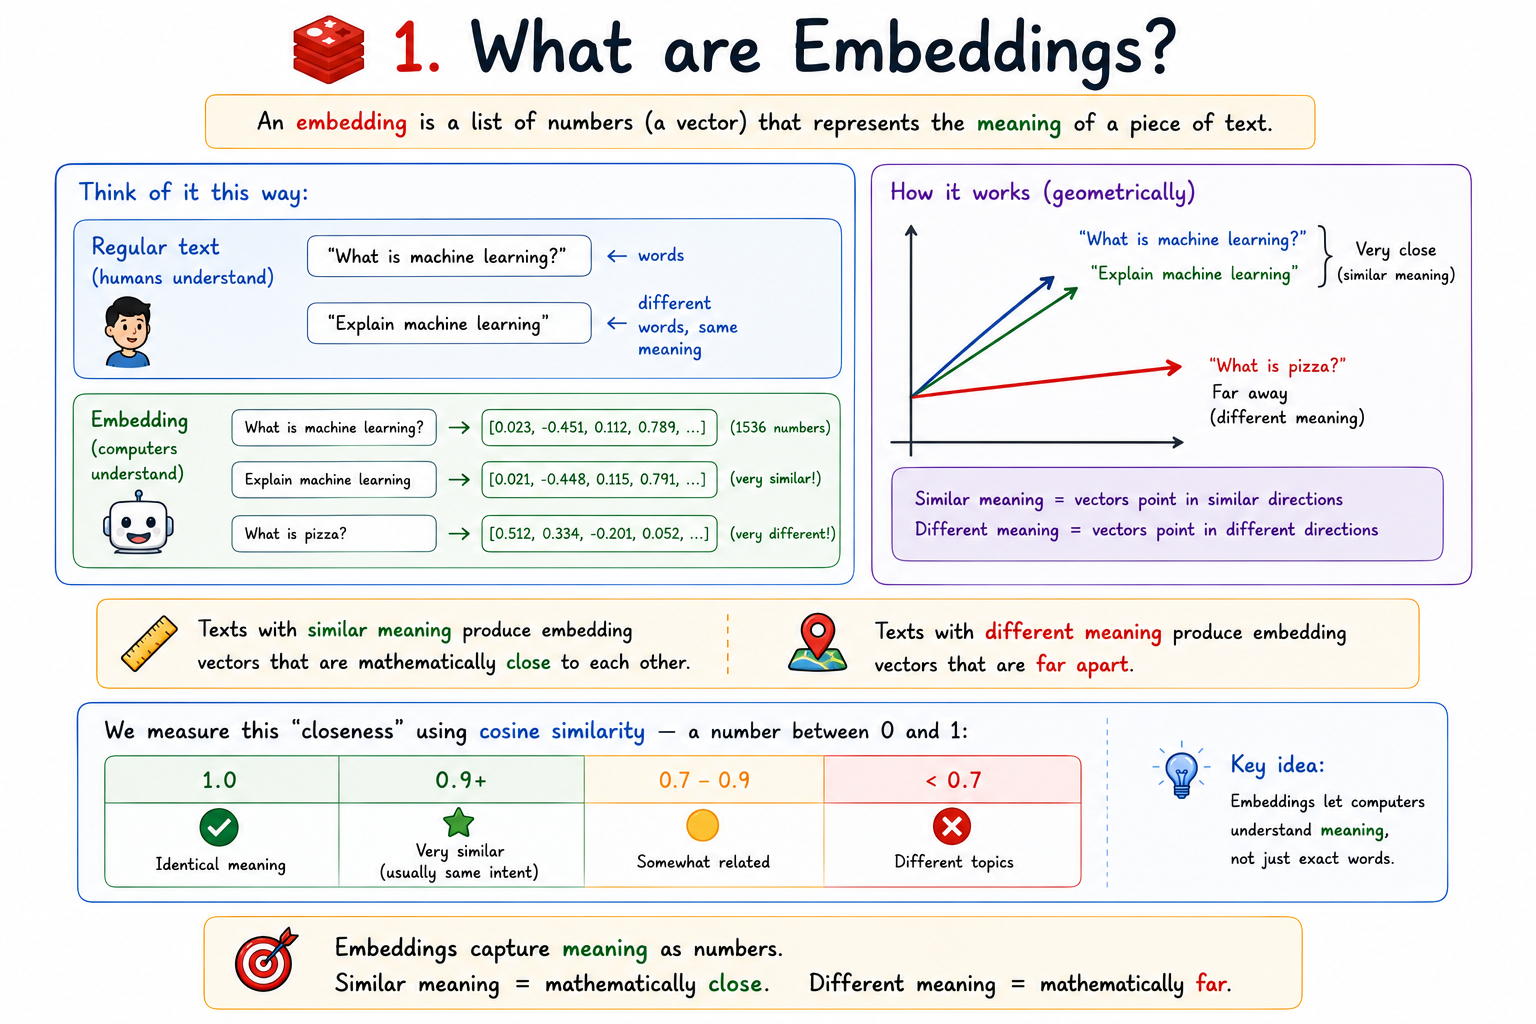

In [2]:
import redis
import openai
import hashlib
import json
import time
import os
import numpy as np
from dotenv import load_dotenv

load_dotenv()

r = redis.Redis(
    host=os.getenv('REDIS_HOST', 'localhost'),
    port=int(os.getenv('REDIS_PORT', 6379)),
    decode_responses=True
)

client = openai.OpenAI(api_key=os.getenv('OPENAI_API_KEY'))

r.ping()
print("Ready!")

Ready!


In [3]:
# ─────────────────────────────────────────────────
# Step 1: Get embeddings from OpenAI
# text-embedding-3-small is fast, cheap, and accurate
# It produces a 1536-dimensional vector
# ─────────────────────────────────────────────────

def get_embedding(text: str) -> list:
    """Convert text to a 1536-dimensional embedding vector."""
    response = client.embeddings.create(
        model="text-embedding-3-small",
        input=text.strip()
    )
    return response.data[0].embedding

# Let's see what an embedding looks like
sample_embedding = get_embedding("What is machine learning?")
print(f"Embedding for 'What is machine learning?'")
print(f"  Type          : {type(sample_embedding)}")
print(f"  Dimensions    : {len(sample_embedding)}")
print(f"  First 5 values: {[round(x, 4) for x in sample_embedding[:5]]}")
print(f"  Last 5 values : {[round(x, 4) for x in sample_embedding[-5:]]}")

Embedding for 'What is machine learning?'
  Type          : <class 'list'>
  Dimensions    : 1536
  First 5 values: [-0.0024, -0.0127, -0.0066, -0.0316, 0.0288]
  Last 5 values : [0.0322, -0.0035, 0.0103, -0.0234, 0.0291]


In [4]:
# ─────────────────────────────────────────────────
# Step 2: Compute cosine similarity between two vectors
# ─────────────────────────────────────────────────

def cosine_similarity(a: list, b: list) -> float:
    """Cosine similarity between two embedding vectors. Returns 0.0 to 1.0."""
    a_arr = np.array(a)
    b_arr = np.array(b)
    dot_product = np.dot(a_arr, b_arr)
    magnitude_a = np.linalg.norm(a_arr)
    magnitude_b = np.linalg.norm(b_arr)
    return float(dot_product / (magnitude_a * magnitude_b))

# Demo: Compare several texts
texts = [
    "What is machine learning?",
    "Can you explain machine learning to me?",
    "Explain ML",
    "Define machine learning",
    "What is deep learning?",   # related but different
    "How do I make pasta?",     # completely unrelated
]

print("Computing embeddings...")
embeddings = {text: get_embedding(text) for text in texts}

reference = "What is machine learning?"
ref_embedding = embeddings[reference]

print(f"\nSimilarity to: '{reference}'")
print("-" * 65)
for text, emb in embeddings.items():
    if text == reference:
        continue
    sim = cosine_similarity(ref_embedding, emb)
    bar = "#" * int(sim * 40)
    print(f"  {sim:.3f}  {bar}")
    print(f"         '{text}'")

Computing embeddings...

Similarity to: 'What is machine learning?'
-----------------------------------------------------------------
  0.710  ############################
         'Can you explain machine learning to me?'
  0.514  ####################
         'Explain ML'
  0.874  ##################################
         'Define machine learning'
  0.597  #######################
         'What is deep learning?'
  0.118  ####
         'How do I make pasta?'


## 2. Understanding the Similarity Threshold

The similarity threshold determines how similar two questions must be to count as a cache hit.

- **Too high (0.99)** — Almost nothing gets cached; only near-identical phrasing
- **Too low (0.50)** — Different questions get the same cached answer (incorrect behavior)
- **Sweet spot (0.70-0.85)** — Questions with the same intent but different wording share the cache

We'll use **0.70** as our default for `text-embedding-3-small`. You can tune it based on your use case.

> **Note:** The right threshold depends on the embedding model. `text-embedding-3-small` produces
> cosine similarities of 0.70–0.90 for paraphrases, so 0.70 is the practical sweet spot.
> Older models like `ada-002` tend to cluster higher (0.90–0.95) for the same pairs.

In [5]:
# Demo: how the threshold affects what counts as a cache hit
test_pairs = [
    ("What is machine learning?", "Can you explain machine learning?"),
    ("What is machine learning?", "Explain ML to me"),
    ("What is machine learning?", "What is deep learning?"),
    ("What is machine learning?", "How do I make pasta?"),
]

thresholds = [0.65, 0.70, 0.75, 0.80]

print(f"{'Text pair':60} | {'Sim':>5} | ", end="")
for t in thresholds:
    print(f"{t:>5}", end=" ")
print()
print("-" * 90)

for t1, t2 in test_pairs:
    e1 = get_embedding(t1)
    e2 = get_embedding(t2)
    sim = cosine_similarity(e1, e2)
    label = f"'{t2[:55]}'" 
    print(f"{label:60} | {sim:.3f} | ", end="")
    for t in thresholds:
        hit = "HIT" if sim >= t else "miss"
        print(f"{hit:>5}", end=" ")
    print()

Text pair                                                    |   Sim |  0.65   0.7  0.75   0.8 
------------------------------------------------------------------------------------------
'Can you explain machine learning?'                          | 0.847 |   HIT   HIT   HIT   HIT 
'Explain ML to me'                                           | 0.461 |  miss  miss  miss  miss 
'What is deep learning?'                                     | 0.597 |  miss  miss  miss  miss 
'How do I make pasta?'                                       | 0.118 |  miss  miss  miss  miss 


## 3. Building the Semantic Cache

The semantic cache stores:
- The original prompt
- The LLM response
- The embedding vector of the prompt (for future similarity searches)

When a new question comes in:
1. Compute its embedding
2. Compare against all cached embeddings using cosine similarity
3. If the best match is above the threshold, return that cached response
4. Otherwise, call the LLM and store the result

In [6]:
SEMANTIC_CACHE_PREFIX = "sem:cache:"
SEMANTIC_INDEX_KEY   = "sem:cache:index"  # Set of all cache entry IDs
SIMILARITY_THRESHOLD = 0.60

# Cost constants (gpt-4o-mini)
COST_INPUT  = 0.00000015
COST_OUTPUT = 0.00000060


def store_in_semantic_cache(prompt: str, response: str, embedding: list):
    """Store a prompt-response pair along with its embedding in Redis."""
    entry_id = hashlib.md5(prompt.encode()).hexdigest()
    key = f"{SEMANTIC_CACHE_PREFIX}{entry_id}"

    # We store embedding as a JSON string (Redis Hashes only store strings)
    r.hset(key, mapping={
        "prompt": prompt,
        "response": response,
        "embedding": json.dumps(embedding),
        "stored_at": str(time.time())
    })
    r.sadd(SEMANTIC_INDEX_KEY, entry_id)  # Track all entry IDs in a Set
    return entry_id


def find_semantic_match(query_embedding: list, threshold: float = SIMILARITY_THRESHOLD):
    """Search all cached embeddings and return the best match if above threshold."""
    entry_ids = r.smembers(SEMANTIC_INDEX_KEY)
    if not entry_ids:
        return None, 0.0

    best_score = 0.0
    best_entry = None

    for entry_id in entry_ids:
        data = r.hgetall(f"{SEMANTIC_CACHE_PREFIX}{entry_id}")
        if not data or "embedding" not in data:
            continue
        cached_embedding = json.loads(data["embedding"])
        score = cosine_similarity(query_embedding, cached_embedding)
        if score > best_score:
            best_score = score
            best_entry = data

    if best_score >= threshold:
        return best_entry, best_score
    return None, best_score


def ask_semantic(prompt: str, threshold: float = SIMILARITY_THRESHOLD) -> dict:
    """Ask LLM with semantic caching."""
    start = time.time()

    # Step 1: Compute embedding for the incoming question
    query_embedding = get_embedding(prompt)
    embed_time = time.time() - start

    # Step 2: Search cache
    match, score = find_semantic_match(query_embedding, threshold)

    if match:
        elapsed_ms = (time.time() - start) * 1000
        return {
            "response": match["response"],
            "source": "SEMANTIC CACHE HIT",
            "similarity": round(score, 4),
            "matched_prompt": match["prompt"],
            "time_ms": round(elapsed_ms, 2),
            "cost_usd": 0.0,
        }

    # Step 3: Cache miss — call the LLM
    api_start = time.time()
    api_response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": prompt}],
        max_tokens=300
    )
    response_text = api_response.choices[0].message.content
    input_tokens  = api_response.usage.prompt_tokens
    output_tokens = api_response.usage.completion_tokens
    cost = (input_tokens * COST_INPUT) + (output_tokens * COST_OUTPUT)

    # Step 4: Store in semantic cache
    store_in_semantic_cache(prompt, response_text, query_embedding)

    elapsed_ms = (time.time() - start) * 1000
    return {
        "response": response_text,
        "source": f"API CALL (best cached similarity: {score:.3f})",
        "similarity": round(score, 4),
        "matched_prompt": None,
        "time_ms": round(elapsed_ms, 2),
        "cost_usd": round(cost, 8),
    }


print("Semantic cache functions defined!")

Semantic cache functions defined!


## 4. Live Demo — Same Intent, Different Wording

In [7]:
# Clear any existing semantic cache
for key in r.keys("sem:cache:*"):
    r.delete(key)
print("Cleared old semantic cache entries")

Cleared old semantic cache entries


In [8]:
# First call — original prompt (will call API and store in cache)
print("\n" + "=" * 60)
print("CALL 1 — Original question")
print("=" * 60)
result = ask_semantic("What is machine learning?")
print(f"Source    : {result['source']}")
print(f"Similarity: {result['similarity']}")
print(f"Time      : {result['time_ms']} ms")
print(f"Cost      : ${result['cost_usd']}")
print(f"Response  : {result['response'][:200]}...")


CALL 1 — Original question
Source    : API CALL (best cached similarity: 0.000)
Similarity: 0.0
Time      : 5572.75 ms
Cost      : $0.0001818
Response  : Machine learning is a subset of artificial intelligence (AI) that focuses on the development of algorithms and statistical models that enable computers to improve their performance on a specific task ...


In [9]:
# Now try semantically similar questions
# These should all hit the semantic cache!

similar_questions = [
    "Can you explain machine learning to me?",
    "What does machine learning mean?",
    "Define machine learning",
    "Explain Machine learning",
    "What is deep learning?",           # related but different concept
    "How do I bake a chocolate cake?",  # completely unrelated
]

print(f"\n{'#':>2}  {'Source':25}  {'Sim':>5}  {'Time(ms)':>8}  Question")
print("-" * 100)

for i, q in enumerate(similar_questions, 2):
    result = ask_semantic(q)
    src_short = "CACHE HIT" if "CACHE HIT" in result["source"] else "API CALL"
    print(f"{i:>2}  {src_short:25}  {result['similarity']:>5.3f}  {result['time_ms']:>8.1f}  {q}")
    if result["matched_prompt"]:
        print(f"    Matched to: '{result['matched_prompt']}'")


 #  Source                       Sim  Time(ms)  Question
----------------------------------------------------------------------------------------------------
 2  CACHE HIT                  0.710     595.0  Can you explain machine learning to me?
    Matched to: 'What is machine learning?'
 3  CACHE HIT                  0.913     374.4  What does machine learning mean?
    Matched to: 'What is machine learning?'
 4  CACHE HIT                  0.874     297.9  Define machine learning
    Matched to: 'What is machine learning?'
 5  CACHE HIT                  0.803     316.3  Explain Machine learning
    Matched to: 'What is machine learning?'
 6  API CALL                   0.597    4761.0  What is deep learning?
 7  API CALL                   0.103    5102.7  How do I bake a chocolate cake?


In [23]:
# How many entries are in the semantic cache now?
index_size = r.scard(SEMANTIC_INDEX_KEY)
print(f"Semantic cache now has {index_size} unique entries")
print()

entry_ids = r.smembers(SEMANTIC_INDEX_KEY)
for entry_id in entry_ids:
    data = r.hgetall(f"{SEMANTIC_CACHE_PREFIX}{entry_id}")
    print(f"  Cached prompt: '{data['prompt']}'")

Semantic cache now has 3 unique entries

  Cached prompt: 'What is machine learning?'
  Cached prompt: 'How do I bake a chocolate cake?'
  Cached prompt: 'What is deep learning?'
